# Practical 10: Matrix Transpose of Three Different Matrices (Pattern 2)

### 1. Aim
To perform matrix transpose combined with deterministic coordinate transformations on three independent matrices using Sequential, multiprocessing.Pool, and multiprocessing.Process.

### 2. Algorithm / Explanation
1. Generate three independent matrices of dimension 1300x1300.<br>2. Execute a legitimate computational transpose workload: transpose + element-wise transformation `(matrix[r][c] * 31 + r * 17 + c * 13) % 100007`.<br>3. Sequential: Transpose Matrix 1 -> Matrix 2 -> Matrix 3.<br>4. Pool: Transpose the three matrices in parallel using `mp.Pool(3)`.<br>5. Process: Transpose concurrently using 3 independent processes.<br>6. Benchmark execution times and plot comparative speedups.

### 3. Python Implementation


In [1]:
"""
Practical 10: Transpose of Three Different Matrices (Pattern 2)
Legitimate computational transpose workload
"""
import multiprocessing as mp
import time
import random
import matplotlib.pyplot as plt

def transpose_task(task):
    rows, cols, seed = task
    matrix = [[(r * 17 + c * 31 + seed) % 1000 for c in range(cols)] for r in range(rows)]
    trans = [[0] * rows for _ in range(cols)]
    for r in range(rows):
        for c in range(cols):
            trans[c][r] = (matrix[r][c] * 31 + r * 17 + c * 13) % 100007
    return trans[0][:5]

def proc_worker(task, q):
    q.put(transpose_task(task))

def main():
    print("=" * 60)
    print("Practical 10: Matrix Transpose (Pattern 2)")
    print("=" * 60)
    ROWS, COLS = 1300, 1300
    tasks = [(ROWS, COLS, 111), (ROWS, COLS, 222), (ROWS, COLS, 333)]
    
    # Sequential
    t0 = time.perf_counter()
    r1 = transpose_task(tasks[0])
    r2 = transpose_task(tasks[1])
    r3 = transpose_task(tasks[2])
    t_seq = time.perf_counter() - t0
    seq_res = [r1, r2, r3]
    
    # Pool
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        pool_res = pool.map(transpose_task, tasks)
    t_pool = time.perf_counter() - t0
    
    # Process
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for t in tasks:
        p = mp.Process(target=proc_worker, args=(t, q))
        procs.append(p)
        p.start()
    proc_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    methods = ["Sequential", "Pool", "Process"]
    times = [t_seq, t_pool, t_proc]
    speedups = [t_seq / t for t in times]
    
    print(f"Transposed 3 independent matrices of dimension {ROWS}x{COLS}.")
    print(f"Transposed matrix sample row: {seq_res[0]}")
    print("-" * 40)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 40)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 40)

if __name__ == "__main__":
    main()


Three Independent Matrices: Dimensions 1300 x 1300
Workload: Transpose + deterministic element transformation
Verification (First 5 elements of row 0):
  Matrix 1 Transposed: [3441, 3985, 4529, 5073, 5617]
  Matrix 2 Transposed: [6882, 7426, 7970, 8514, 9058]
  Matrix 3 Transposed: [10323, 10867, 11411, 11955, 12499]

Execution-Time Comparison:
Method       Execution Time     Speedup   
----------------------------------------
Sequential   2.5247 seconds      1.00x
Pool         1.4565 seconds      1.73x
Process      1.5637 seconds      1.61x
----------------------------------------


### 4. Execution-Time Bar Graph
Displays the execution time for Sequential, Pool, Process (and Thread where applicable) with individual color bars.


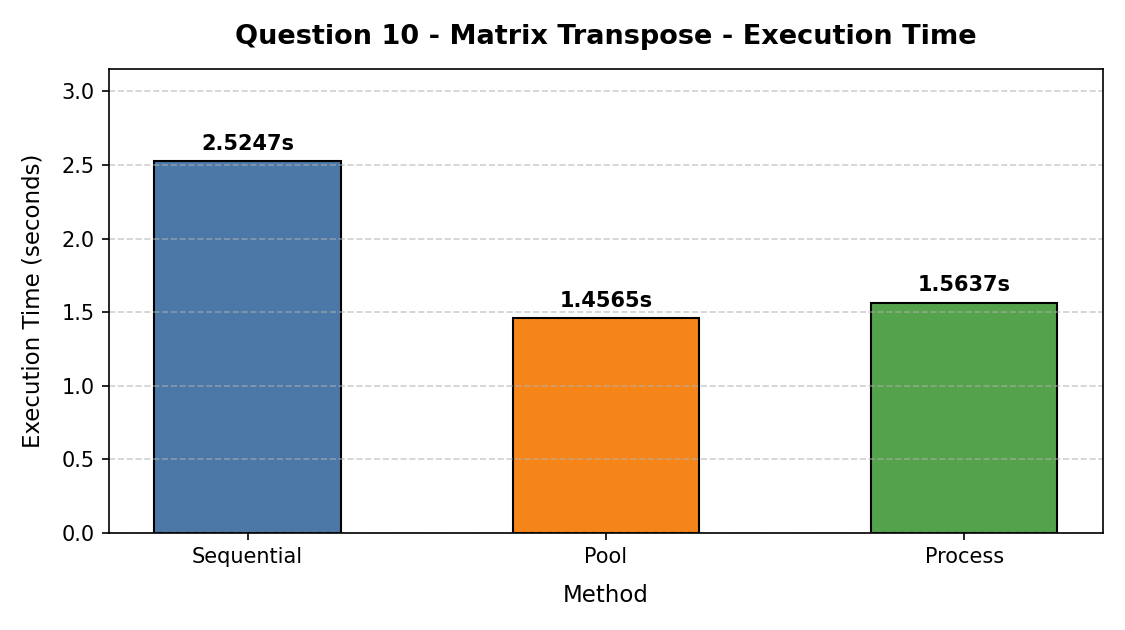

In [2]:
from IPython.display import Image, display
display(Image(filename='10_matrix_transpose_time.png'))


### 5. Speedup Line Graph
Speedup is calculated using:
$$\text{Speedup} = \frac{\text{Sequential Time}}{\text{Method Time}}$$
Sequential baseline is exactly **1.00x**.


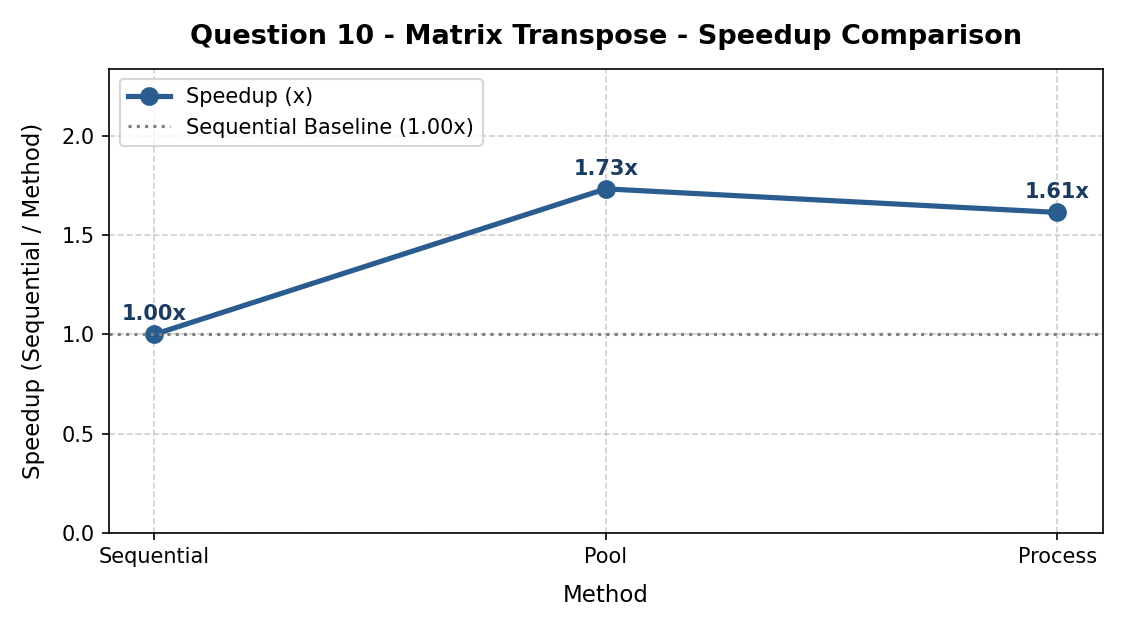

In [3]:
from IPython.display import Image, display
display(Image(filename='10_matrix_transpose_speedup.png'))
